<a href="https://colab.research.google.com/github/Elder-stack/LHUD-Capstone-Ivan/blob/main/RealEstateAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Purpose: To load the four original HDB resale datasets and check their sizes.
import pandas as pd

# Load the four original CSV files from GitHub
df_2000 = pd.read_csv('https://raw.githubusercontent.com/Elder-stack/LHUD-Capstone-Ivan/main/resale-flat-prices-based-on-approval-date-2000-feb-2012.csv')

df_2012 = pd.read_csv('https://raw.githubusercontent.com/Elder-stack/LHUD-Capstone-Ivan/main/resale-flat-prices-based-on-registration-date-from-mar-2012-to-dec-2014.csv')

df_2015 = pd.read_csv('https://raw.githubusercontent.com/Elder-stack/LHUD-Capstone-Ivan/main/resale-flat-prices-based-on-registration-date-from-jan-2015-to-dec-2016.csv')

df_2017 = pd.read_csv('https://raw.githubusercontent.com/Elder-stack/LHUD-Capstone-Ivan/main/ResaleflatpricesbasedonregistrationdatefromJan2017onwards.csv')

# Check the number of rows and columns
print("2000 to Feb 2012:", df_2000.shape)
print("Mar 2012 to Dec 2014:", df_2012.shape)
print("Jan 2015 to Dec 2016:", df_2015.shape)
print("Jan 2017 onwards:", df_2017.shape)

# Result: Shows the number of rows and columns in each original dataset.

2000 to Feb 2012: (369651, 10)
Mar 2012 to Dec 2014: (52203, 10)
Jan 2015 to Dec 2016: (37153, 11)
Jan 2017 onwards: (169584, 11)


In [2]:
# Purpose: To check missing values, duplicate rows and data types in the HDB dataset.
# Combine the four original datasets
df = pd.concat([df_2000, df_2012, df_2015, df_2017], ignore_index=True)

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

# Check data types
print("\nData Types:")
print(df.dtypes)

# Result: Shows missing values, duplicate rows and data types that may need cleaning.

Missing Values:
month                       0
town                        0
flat_type                   0
block                       0
street_name                 0
storey_range                0
floor_area_sqm              0
flat_model                  0
lease_commence_date         0
resale_price                0
remaining_lease        421854
dtype: int64

Duplicate Rows:
1066

Data Types:
month                   object
town                    object
flat_type               object
block                   object
street_name             object
storey_range            object
floor_area_sqm         float64
flat_model              object
lease_commence_date      int64
resale_price           float64
remaining_lease         object
dtype: object


In [3]:
# Purpose: To check which years have missing remaining lease values.
# Create a year column from the transaction month
df['year'] = pd.to_datetime(df['month']).dt.year

# Count missing remaining lease values by year
print(df[df['remaining_lease'].isnull()].groupby('year').size())

# Result: Shows the number of missing remaining lease values for each year.

year
2000    34862
2001    38055
2002    36098
2003    29003
2004    29112
2005    30045
2006    27427
2007    26982
2008    27262
2009    30482
2010    34854
2011    22281
2012    23198
2013    16097
2014    16096
dtype: int64


In [4]:
# Purpose: To estimate the missing remaining lease using the lease commencement year.
# Calculate remaining lease for records with missing values
df['remaining_lease_estimated'] = 99 - (df['year'] - df['lease_commence_date'])

# Check the first 5 rows
print(df[['year', 'lease_commence_date', 'remaining_lease', 'remaining_lease_estimated']].head())

# Check for unusual estimated values
print("\nEstimated Lease Summary:")
print(df['remaining_lease_estimated'].describe())

# Result: Shows the estimated remaining lease based on a 99-year lease assumption.

   year  lease_commence_date remaining_lease  remaining_lease_estimated
0  2000                 1986             NaN                         85
1  2000                 1986             NaN                         85
2  2000                 1976             NaN                         75
3  2000                 1976             NaN                         75
4  2000                 1976             NaN                         75

Estimated Lease Summary:
count    628591.000000
mean         78.880730
std          11.417491
min          42.000000
25%          71.000000
50%          79.000000
75%          89.000000
max         101.000000
Name: remaining_lease_estimated, dtype: float64


In [5]:
# Purpose: To check the dataset size and identify unusual lease values.
# Check total rows and columns
print("Dataset Shape:")
print(df.shape)

# Check estimated leases above 99 years
print("\nEstimated Lease Above 99 Years:")
print((df['remaining_lease_estimated'] > 99).sum())

# Check estimated leases below 0 years
print("\nEstimated Lease Below 0 Years:")
print((df['remaining_lease_estimated'] < 0).sum())

# Check the affected records
print("\nRecords with Estimated Lease Above 99 Years:")
print(df[df['remaining_lease_estimated'] > 99][
    ['month', 'town', 'lease_commence_date', 'remaining_lease_estimated']
].head(10))

# Result: Shows the dataset size and identifies estimated lease values that need checking.

Dataset Shape:
(628591, 13)

Estimated Lease Above 99 Years:
15

Estimated Lease Below 0 Years:
0

Records with Estimated Lease Above 99 Years:
          month         town  lease_commence_date  remaining_lease_estimated
157846  2004-09  BUKIT MERAH                 2006                        101
162626  2004-11  BUKIT MERAH                 2006                        101
167746  2005-01  BUKIT MERAH                 2006                        100
167747  2005-01  BUKIT MERAH                 2006                        100
172852  2005-03  BUKIT MERAH                 2006                        100
175738  2005-04  BUKIT MERAH                 2006                        100
178191  2005-05  BUKIT MERAH                 2006                        100
180141  2005-06   ANG MO KIO                 2006                        100
182635  2005-07   ANG MO KIO                 2006                        100
182636  2005-07   ANG MO KIO                 2006                        100


In [6]:
# Purpose: To check the number of records in each original dataset.
print("2000 to Feb 2012:", df_2000.shape)
print("Mar 2012 to Dec 2014:", df_2012.shape)
print("Jan 2015 to Dec 2016:", df_2015.shape)
print("Jan 2017 onwards:", df_2017.shape)

# Check the total number of records
total = len(df_2000) + len(df_2012) + len(df_2015) + len(df_2017)

print("\nTotal Original Records:", total)
print("Combined Dataset Records:", len(df))

# Result: Shows whether the combined dataset contains all records from the four original CSV files.

2000 to Feb 2012: (369651, 10)
Mar 2012 to Dec 2014: (52203, 10)
Jan 2015 to Dec 2016: (37153, 11)
Jan 2017 onwards: (169584, 11)

Total Original Records: 628591
Combined Dataset Records: 628591


In [7]:
# Purpose: To check how many duplicate records are in the HDB dataset.
# Check total duplicate rows
print("Total Duplicate Rows:", df.duplicated().sum())

# Display the first 10 duplicate records
print("\nSample Duplicate Records:")
display(df[df.duplicated(keep=False)].head(10))

# Result: Shows the number of duplicate records and examples for checking.

Total Duplicate Rows: 1066

Sample Duplicate Records:


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,resale_price,remaining_lease,year,remaining_lease_estimated
21,2000-01,ANG MO KIO,3 ROOM,443,ANG MO KIO AVE 10,07 TO 09,67.0,New Generation,1979,162000.0,NaN,2000,78
22,2000-01,ANG MO KIO,3 ROOM,443,ANG MO KIO AVE 10,07 TO 09,67.0,New Generation,1979,162000.0,NaN,2000,78
175,2000-01,BEDOK,3 ROOM,32,CHAI CHEE AVE,13 TO 15,65.0,Improved,1974,165000.0,NaN,2000,73
176,2000-01,BEDOK,3 ROOM,32,CHAI CHEE AVE,13 TO 15,65.0,Improved,1974,165000.0,NaN,2000,73
284,2000-01,BEDOK,4 ROOM,421,BEDOK NTH RD,13 TO 15,92.0,New Generation,1979,275000.0,NaN,2000,78
285,2000-01,BEDOK,4 ROOM,421,BEDOK NTH RD,13 TO 15,92.0,New Generation,1979,275000.0,NaN,2000,78
867,2000-01,CLEMENTI,3 ROOM,518,WEST COAST RD,10 TO 12,68.0,New Generation,1980,154000.0,NaN,2000,79
868,2000-01,CLEMENTI,3 ROOM,518,WEST COAST RD,10 TO 12,68.0,New Generation,1980,154000.0,NaN,2000,79
2326,2000-01,YISHUN,4 ROOM,249,YISHUN AVE 9,10 TO 12,84.0,Simplified,1985,195000.0,NaN,2000,84
2327,2000-01,YISHUN,4 ROOM,249,YISHUN AVE 9,10 TO 12,84.0,Simplified,1985,195000.0,NaN,2000,84


In [8]:
# Purpose: To check which years contain duplicate HDB resale records.
# Find duplicate records
duplicates = df[df.duplicated()]

# Count duplicates by year
print("Duplicate Records by Year:")
print(duplicates.groupby('year').size())

# Calculate percentage of duplicates
print("\nDuplicate Percentage:")
print(round(df.duplicated().sum() / len(df) * 100, 2), "%")

# Result: Shows which years have duplicate records and their percentage of the dataset.

Duplicate Records by Year:
year
2000     73
2001     88
2002     75
2003     32
2004     26
2005     34
2006     38
2007     20
2008     23
2009     46
2010     38
2011     19
2012     12
2013     11
2014    226
2015     14
2016     10
2017    172
2018      9
2019     18
2020     20
2021     30
2022     18
2023     14
dtype: int64

Duplicate Percentage:
0.17 %


In [9]:
# Purpose: To check for unusual resale prices and floor areas before cleaning.
# Check resale price statistics
print("Resale Price Summary:")
print(df['resale_price'].describe())

# Check floor area statistics
print("\nFloor Area Summary:")
print(df['floor_area_sqm'].describe())

# Check zero or negative values
print("\nInvalid Resale Prices:")
print((df['resale_price'] <= 0).sum())

print("\nInvalid Floor Areas:")
print((df['floor_area_sqm'] <= 0).sum())

# Result: Shows the minimum, maximum and average values,
# and checks for invalid prices or floor areas.

Resale Price Summary:
count    6.285910e+05
mean     3.620510e+05
std      1.643300e+05
min      2.800000e+04
25%      2.400000e+05
50%      3.380000e+05
75%      4.500000e+05
max      1.500000e+06
Name: resale_price, dtype: float64

Floor Area Summary:
count    628591.000000
mean         96.767132
std          25.051891
min          28.000000
25%          74.000000
50%          96.000000
75%         113.000000
max         297.000000
Name: floor_area_sqm, dtype: float64

Invalid Resale Prices:
0

Invalid Floor Areas:
0


In [10]:
# Purpose: To check the different flat types and towns in the HDB dataset.
# Check flat types
print("Flat Types:")
print(df['flat_type'].value_counts())

# Check towns
print("\nTowns:")
print(df['town'].value_counts())

# Check number of unique flat types and towns
print("\nNumber of Flat Types:", df['flat_type'].nunique())
print("Number of Towns:", df['town'].nunique())

# Result: Shows the flat types and towns available for comparison in our analysis.

Flat Types:
flat_type
4 ROOM              248960
3 ROOM              180081
5 ROOM              144616
EXECUTIVE            46835
2 ROOM                7366
1 ROOM                 473
MULTI-GENERATION       260
Name: count, dtype: int64

Towns:
town
WOODLANDS          55028
TAMPINES           48480
JURONG WEST        46656
YISHUN             41503
BEDOK              38939
HOUGANG            34173
SENGKANG           31532
ANG MO KIO         31192
CHOA CHU KANG      29136
BUKIT BATOK        27333
BUKIT MERAH        23322
PASIR RIS          22025
BUKIT PANJANG      21743
TOA PAYOH          20287
PUNGGOL            19835
QUEENSTOWN         18721
KALLANG/WHAMPOA    18126
GEYLANG            17467
CLEMENTI           16473
JURONG EAST        15499
SERANGOON          14115
SEMBAWANG          13421
BISHAN             12794
MARINE PARADE       4657
CENTRAL AREA        4583
BUKIT TIMAH         1551
Name: count, dtype: int64

Number of Flat Types: 7
Number of Towns: 26


In [11]:
# Purpose: To check the earliest and latest HDB resale transaction dates.
# Convert month into date format
df['month'] = pd.to_datetime(df['month'])

# Check earliest and latest dates
print("Earliest Transaction:", df['month'].min())
print("Latest Transaction:", df['month'].max())

# Check number of transactions by year
print("\nTransactions by Year:")
print(df['year'].value_counts().sort_index())

# Result: Shows the period covered by the dataset and the number of resale transactions each year.

Earliest Transaction: 2000-01-01 00:00:00
Latest Transaction: 2024-01-01 00:00:00

Transactions by Year:
year
2000    34862
2001    38055
2002    36098
2003    29003
2004    29112
2005    30045
2006    27427
2007    26982
2008    27262
2009    30482
2010    34854
2011    22281
2012    23198
2013    16097
2014    16096
2015    17780
2016    19373
2017    20509
2018    21561
2019    22186
2020    23333
2021    29087
2022    26720
2023    25777
2024      411
Name: count, dtype: int64


In [12]:
# Purpose: To exclude the incomplete year 2024 from yearly comparisons.
# Keep transactions from 2000 to 2023
df_analysis = df[df['year'] <= 2023].copy()

# Check the number of records
print("Original Dataset:", len(df))
print("Analysis Dataset:", len(df_analysis))

# Check the latest year
print("Latest Analysis Year:", df_analysis['year'].max())

# Result: The analysis dataset excludes 2024 so that yearly comparisons use complete calendar years.

Original Dataset: 628591
Analysis Dataset: 628180
Latest Analysis Year: 2023


In [13]:
# Purpose: To calculate the resale price per square metre for comparing flats of different sizes.
# Calculate price per square metre
df_analysis['price_per_sqm'] = df_analysis['resale_price'] / df_analysis['floor_area_sqm']

# Display the first 5 rows
print(df_analysis[['resale_price', 'floor_area_sqm', 'price_per_sqm']].head())

# Check price per square metre statistics
print("\nPrice per Square Metre Summary:")
print(df_analysis['price_per_sqm'].describe())

# Result: Shows the resale price per square metre for comparing HDB flats of different sizes.

   resale_price  floor_area_sqm  price_per_sqm
0      147000.0            69.0    2130.434783
1      144000.0            61.0    2360.655738
2      159000.0            73.0    2178.082192
3      167000.0            73.0    2287.671233
4      163000.0            67.0    2432.835821

Price per Square Metre Summary:
count    628180.000000
mean       3755.974234
std        1472.134574
min         662.337662
25%        2537.313433
50%        3552.941176
75%        4619.047619
max       15170.838710
Name: price_per_sqm, dtype: float64


In [14]:
# Purpose: To check the estimated remaining lease before using it for analysis.
# Check estimated remaining lease values
print("Estimated Remaining Lease Summary:")
print(df_analysis['remaining_lease_estimated'].describe())

# Check unusual lease values
print("\nEstimated Lease Above 99 Years:")
print((df_analysis['remaining_lease_estimated'] > 99).sum())

# Check missing values
print("\nMissing Estimated Lease Values:")
print(df_analysis['remaining_lease_estimated'].isnull().sum())

# Result: Shows the estimated remaining lease values and identifies any unusual or missing values.

Estimated Remaining Lease Summary:
count    628180.000000
mean         78.884479
std          11.414241
min          42.000000
25%          71.000000
50%          79.000000
75%          89.000000
max         101.000000
Name: remaining_lease_estimated, dtype: float64

Estimated Lease Above 99 Years:
15

Missing Estimated Lease Values:
0


In [15]:
# Purpose: To handle estimated remaining lease values above 99 years.
# Create a new column for lease analysis
df_analysis['lease_for_analysis'] = df_analysis['remaining_lease_estimated']

# Set estimated leases above 99 years as missing
df_analysis.loc[
    df_analysis['lease_for_analysis'] > 99,
    'lease_for_analysis'
] = None

# Check the results
print("Missing Lease Values for Analysis:")
print(df_analysis['lease_for_analysis'].isnull().sum())

print("\nLease Values Above 99 Years:")
print((df_analysis['lease_for_analysis'] > 99).sum())

print("\nLease Summary:")
print(df_analysis['lease_for_analysis'].describe())

# Result: The 15 unusual lease estimates are marked as missing
# without deleting the transaction records.

Missing Lease Values for Analysis:
15

Lease Values Above 99 Years:
0

Lease Summary:
count    628165.000000
mean         78.883972
std          11.413905
min          42.000000
25%          71.000000
50%          79.000000
75%          89.000000
max          99.000000
Name: lease_for_analysis, dtype: float64


In [16]:
# Purpose: To check the final dataset before starting the analysis.
print("Total Records:", len(df_analysis))

print("\nMissing Values:")
print(df_analysis.isnull().sum())

print("\nDuplicate Rows:")
print(df_analysis.duplicated().sum())

print("\nData Types:")
print(df_analysis.dtypes)

# Result: Shows the total records, missing values,
# duplicate rows and data types in the analysis dataset.

Total Records: 628180

Missing Values:
month                             0
town                              0
flat_type                         0
block                             0
street_name                       0
storey_range                      0
floor_area_sqm                    0
flat_model                        0
lease_commence_date               0
resale_price                      0
remaining_lease              421854
year                              0
remaining_lease_estimated         0
price_per_sqm                     0
lease_for_analysis               15
dtype: int64

Duplicate Rows:
1066

Data Types:
month                        datetime64[ns]
town                                 object
flat_type                            object
block                                object
street_name                          object
storey_range                         object
floor_area_sqm                      float64
flat_model                           object
lease_commence_date  

In [17]:
# Purpose: To save the prepared HDB dataset for analysis and visualisation.
# Save the dataset as a CSV file
df_analysis.to_csv('HDB_Resale_Prepared.csv', index=False)

# Check the saved file
import os

print("File Saved:", os.path.exists('HDB_Resale_Prepared.csv'))
print("Total Records:", len(df_analysis))
print("Total Columns:", len(df_analysis.columns))

# Result: The prepared HDB dataset is saved as a CSV file with
# 628,180 records and 15 columns for further analysis.

File Saved: True
Total Records: 628180
Total Columns: 15


# Exploratory Data Analysis (EDA)
The following analysis uses HDB resale transaction data from 2000 to 2023.

The charts are organised according to the five research objectives to understand resale market activity, price trends, property characteristics, relative housing costs and differences across towns.


## Objective 1: Housing Demand & Market Activity
To analyse HDB resale transaction volumes from 2000 to 2023 and identify which flat types have the highest transaction volumes.


In [18]:
# Purpose: To analyse the number of HDB resale transactions each year from 2000 to 2023.
# Count resale transactions by year
yearly_transactions = df_analysis.groupby('year').size()

# Display the results
print("HDB Resale Transactions by Year:")
print(yearly_transactions)

# Result: Shows the number of resale transactions each year
# to understand changes in HDB resale market activity.

HDB Resale Transactions by Year:
year
2000    34862
2001    38055
2002    36098
2003    29003
2004    29112
2005    30045
2006    27427
2007    26982
2008    27262
2009    30482
2010    34854
2011    22281
2012    23198
2013    16097
2014    16096
2015    17780
2016    19373
2017    20509
2018    21561
2019    22186
2020    23333
2021    29087
2022    26720
2023    25777
dtype: int64


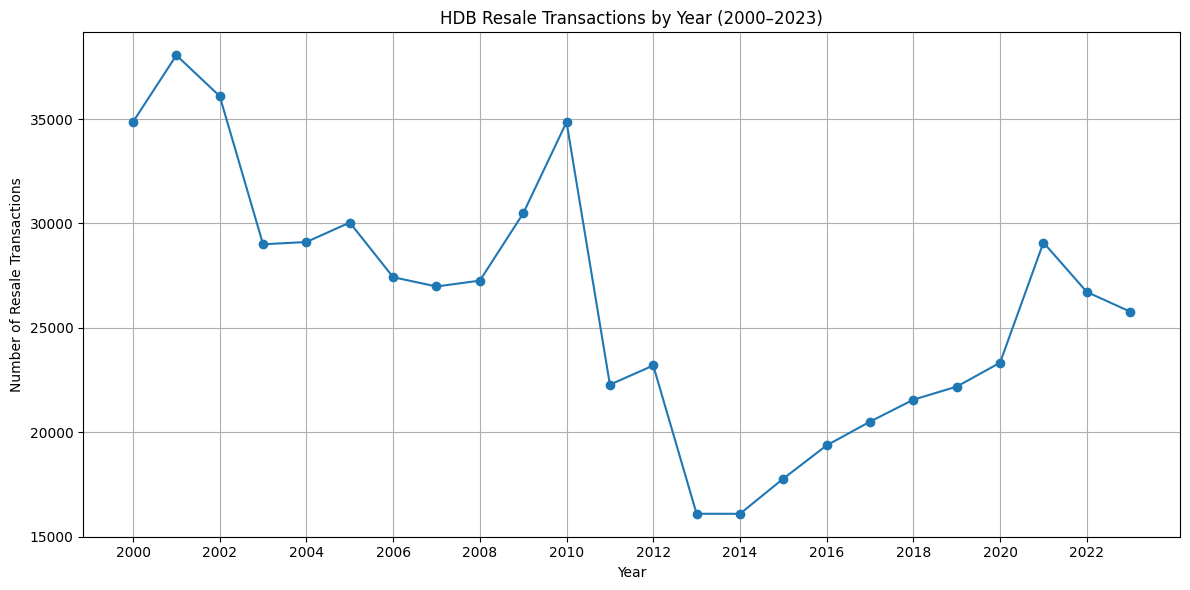

In [19]:
# Purpose: To show the trend of HDB resale transactions from 2000 to 2023.
import matplotlib.pyplot as plt

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(yearly_transactions.index, yearly_transactions.values, marker='o')

# Add chart title and labels
plt.title('HDB Resale Transactions by Year (2000–2023)')
plt.xlabel('Year')
plt.ylabel('Number of Resale Transactions')

# Improve chart readability
plt.xticks(range(2000, 2024, 2))
plt.grid(True)
plt.tight_layout()

# Display chart
plt.show()

# Result: Resale transactions were highest in 2001 (38,055)
# and lowest in 2014 (16,096), showing changes in resale market activity.

HDB Resale Transactions by Flat Type:
flat_type
4 ROOM              248780
3 ROOM              179988
5 ROOM              144521
EXECUTIVE            46807
2 ROOM                7351
1 ROOM                 473
MULTI-GENERATION       260
Name: count, dtype: int64


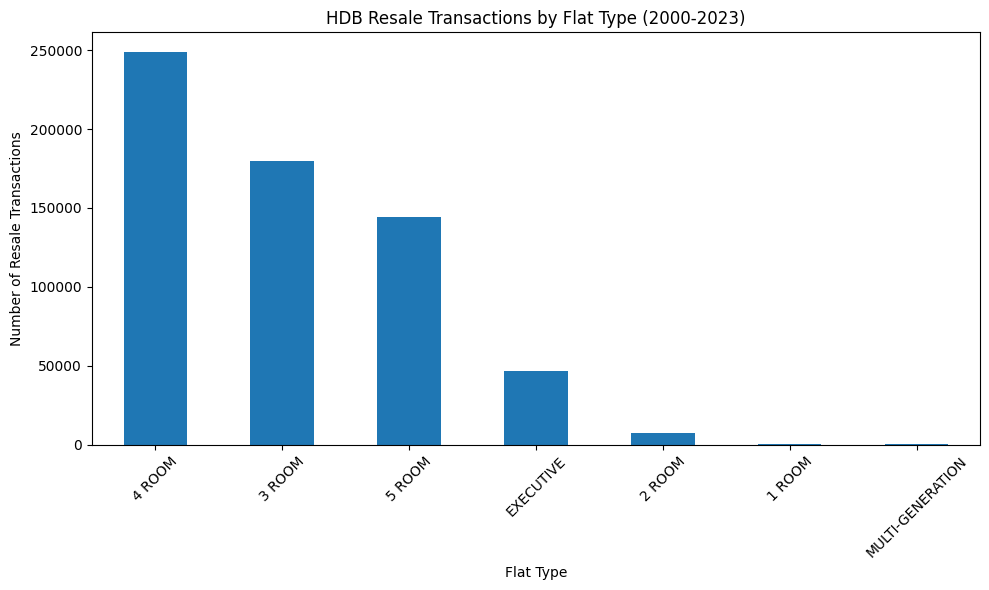

In [33]:
# Purpose: To compare HDB resale transaction volumes by flat type.
# Count transactions by flat type
flat_type_volume = df_analysis['flat_type'].value_counts()

# Display results
print("HDB Resale Transactions by Flat Type:")
print(flat_type_volume)

# Create bar chart
plt.figure(figsize=(10, 6))
flat_type_volume.plot(kind='bar')

# Add chart title and labels
plt.title('HDB Resale Transactions by Flat Type (2000-2023)')
plt.xlabel('Flat Type')
plt.ylabel('Number of Resale Transactions')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Result: Shows which flat types have the highest
# resale transaction volumes from 2000 to 2023.


### Key Finding
HDB resale transaction volumes fluctuated between 2000 and 2023. The highest transaction volume was 38,055 in 2001.

Four-room flats recorded the highest number of resale transactions, showing that they had the most resale market activity during the analysis period.


## Objective 2: Resale Price Trends & Market Cycles
To analyse historical HDB resale price trends from 2000 to 2023 and identify changes in resale prices over time.


Median HDB Resale Price by Year:
year
2000    239000.0
2001    225000.0
2002    215000.0
2003    217000.0
2004    223500.0
2005    225000.0
2006    228000.0
2007    250000.0
2008    305000.0
2009    330000.0
2010    365944.0
2011    410000.0
2012    445000.0
2013    455000.0
2014    420000.0
2015    405000.0
2016    410000.0
2017    410000.0
2018    408000.0
2019    400000.0
2020    425000.0
2021    483000.0
2022    525000.0
2023    550000.0
Name: resale_price, dtype: float64


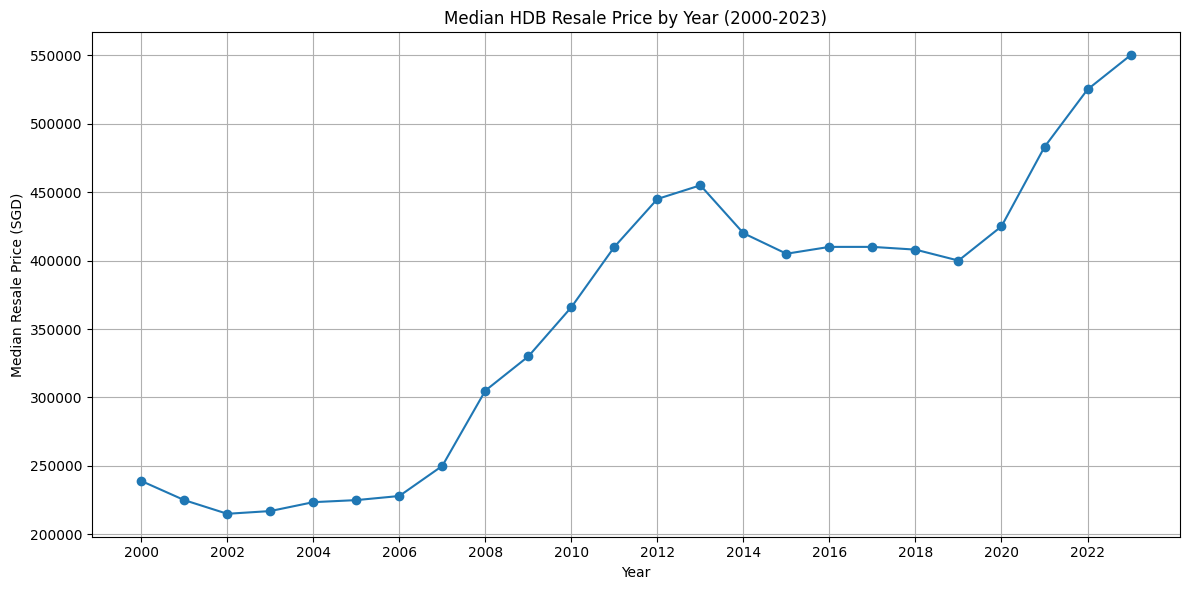

In [20]:
# Purpose: To analyse how HDB median resale prices changed from 2000 to 2023.
# Calculate median resale price by year
yearly_prices = df_analysis.groupby('year')['resale_price'].median()

# Display the results
print("Median HDB Resale Price by Year:")
print(yearly_prices)

# Create line chart
plt.figure(figsize=(12, 6))
plt.plot(yearly_prices.index, yearly_prices.values, marker='o')

# Add chart title and labels
plt.title('Median HDB Resale Price by Year (2000-2023)')
plt.xlabel('Year')
plt.ylabel('Median Resale Price (SGD)')

# Improve chart readability
plt.xticks(range(2000, 2024, 2))
plt.grid(True)
plt.tight_layout()

# Display chart
plt.show()

# Result: Median resale prices increased from $239,000 in 2000
# to $550,000 in 2023, showing an overall upward price trend.

### Key Finding
The median HDB resale price increased from S$239,000 in 2000 to S$550,000 in 2023.

Although resale prices fluctuated over the years, the overall trend shows an increase in HDB resale prices.


## Objective 3: Property Valuation Drivers
To examine how floor area, remaining lease and storey range relate to HDB resale prices.


In [36]:
# Purpose: To select 2023 transactions for property comparisons.
df_2023 = df_analysis[df_analysis['year'] == 2023]

print("Total HDB Resale Transactions in 2023:", len(df_2023))

Total HDB Resale Transactions in 2023: 25777


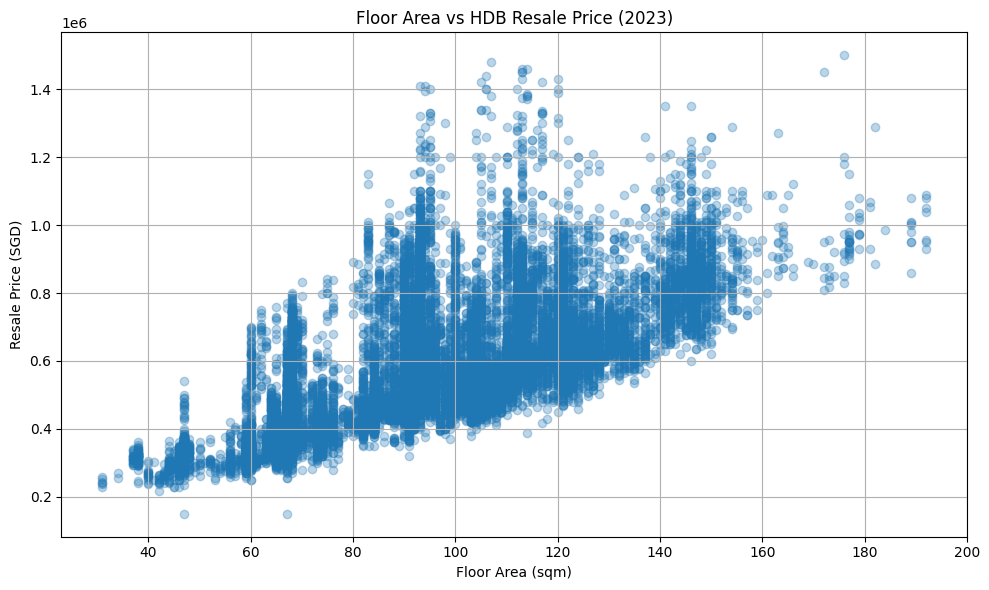

Correlation between Floor Area and Resale Price:
0.6826331393263206


In [26]:
# Purpose: To check the relationship between floor area and resale price in 2023.
# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(df_2023['floor_area_sqm'], df_2023['resale_price'], alpha=0.3)

# Add chart title and labels
plt.title('Floor Area vs HDB Resale Price (2023)')
plt.xlabel('Floor Area (sqm)')
plt.ylabel('Resale Price (SGD)')

plt.grid(True)
plt.tight_layout()
plt.show()

# Check correlation
print("Correlation between Floor Area and Resale Price:")
print(df_2023['floor_area_sqm'].corr(df_2023['resale_price']))

# Result: The correlation is 0.683, showing that larger flats
# generally have higher resale prices in 2023.

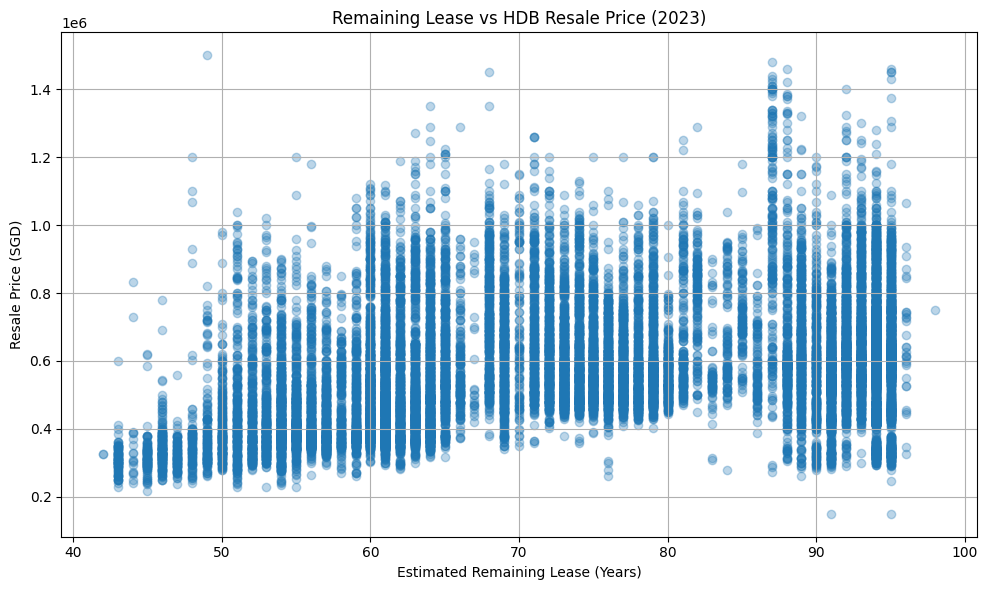

Correlation between Remaining Lease and Resale Price:
0.3670935816326898


In [27]:
# Purpose: To check the relationship between remaining lease and resale price in 2023.
# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(df_2023['lease_for_analysis'],
            df_2023['resale_price'], alpha=0.3)

# Add chart title and labels
plt.title('Remaining Lease vs HDB Resale Price (2023)')
plt.xlabel('Estimated Remaining Lease (Years)')
plt.ylabel('Resale Price (SGD)')

plt.grid(True)
plt.tight_layout()
plt.show()

# Check correlation
print("Correlation between Remaining Lease and Resale Price:")
print(df_2023['lease_for_analysis'].corr(df_2023['resale_price']))

# Result: The correlation is 0.367, showing a positive relationship
# between estimated remaining lease and resale price in 2023.

Median Resale Price by Storey Range in 2023:
storey_range
01 TO 03     502000.0
04 TO 06     525000.0
07 TO 09     545000.0
10 TO 12     550888.0
13 TO 15     600000.0
16 TO 18     625888.0
19 TO 21     694500.0
22 TO 24     736944.0
25 TO 27     759000.0
28 TO 30     920000.0
31 TO 33     930000.0
34 TO 36     950000.0
37 TO 39     950000.0
40 TO 42    1000000.0
43 TO 45    1230000.0
46 TO 48    1320000.0
49 TO 51    1401969.5
Name: resale_price, dtype: float64


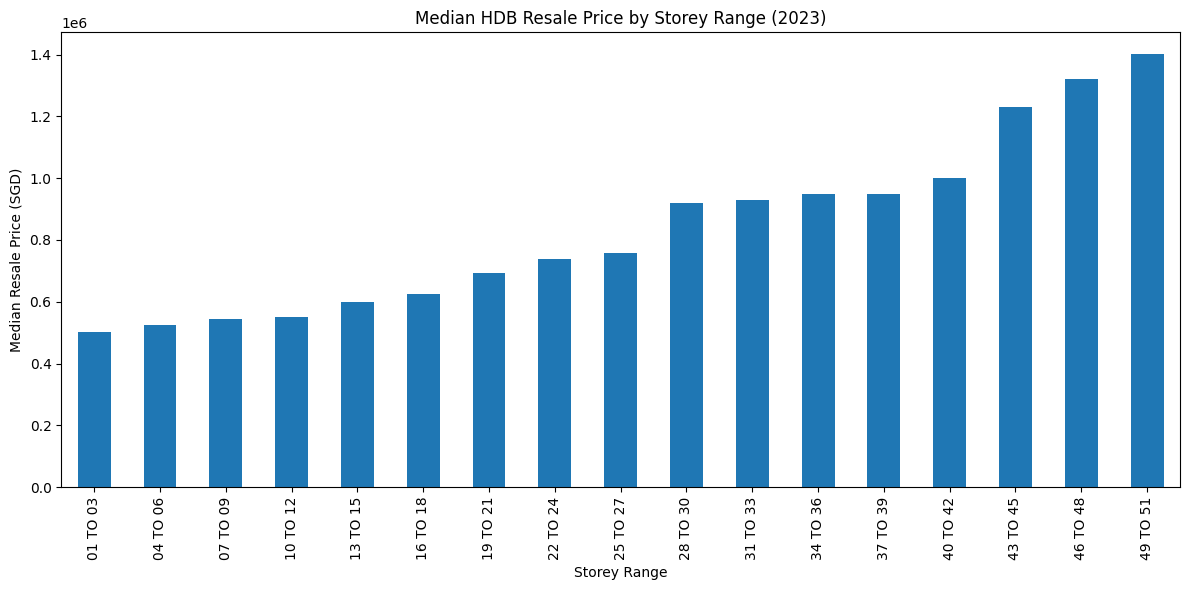

In [28]:
# Purpose: To compare median HDB resale prices across different storey ranges in 2023.
# Calculate median resale price by storey range
storey_prices_2023 = df_2023.groupby('storey_range')['resale_price'].median()

# Sort the storey ranges
storey_prices_2023 = storey_prices_2023.sort_index()

# Display results
print("Median Resale Price by Storey Range in 2023:")
print(storey_prices_2023)

# Create bar chart
plt.figure(figsize=(12, 6))
storey_prices_2023.plot(kind='bar')

# Add chart title and labels
plt.title('Median HDB Resale Price by Storey Range (2023)')
plt.xlabel('Storey Range')
plt.ylabel('Median Resale Price (SGD)')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Result: Median resale prices generally increased with higher storey ranges.
# Flats on floors 01 to 03 had a median price of $502,000,
# compared to $1,401,969.50 for floors 49 to 51 in 2023.

In [34]:
# Purpose: To select 2023 transactions for property comparisons.
df_2023 = df_analysis[df_analysis['year'] == 2023]

print("Total HDB Resale Transactions in 2023:", len(df_2023))


Total HDB Resale Transactions in 2023: 25777


### Key Finding
Floor area had a positive correlation of 0.683 with resale price in 2023, showing that larger flats generally had higher prices.

Estimated remaining lease had a weaker positive correlation of 0.367 with resale price. Median resale prices also generally increased across higher storey ranges.

These results suggest that floor area, remaining lease and storey range are related to HDB resale prices.


## Objective 4: Housing Affordability & Relative Housing Costs
To compare HDB resale prices and price per square metre across different flat types and towns.


Median Resale Price by Flat Type:
flat_type
1 ROOM               78000.0
2 ROOM              220000.0
3 ROOM              232500.0
4 ROOM              341000.0
5 ROOM              425000.0
EXECUTIVE           515800.0
MULTI-GENERATION    550000.0
Name: resale_price, dtype: float64


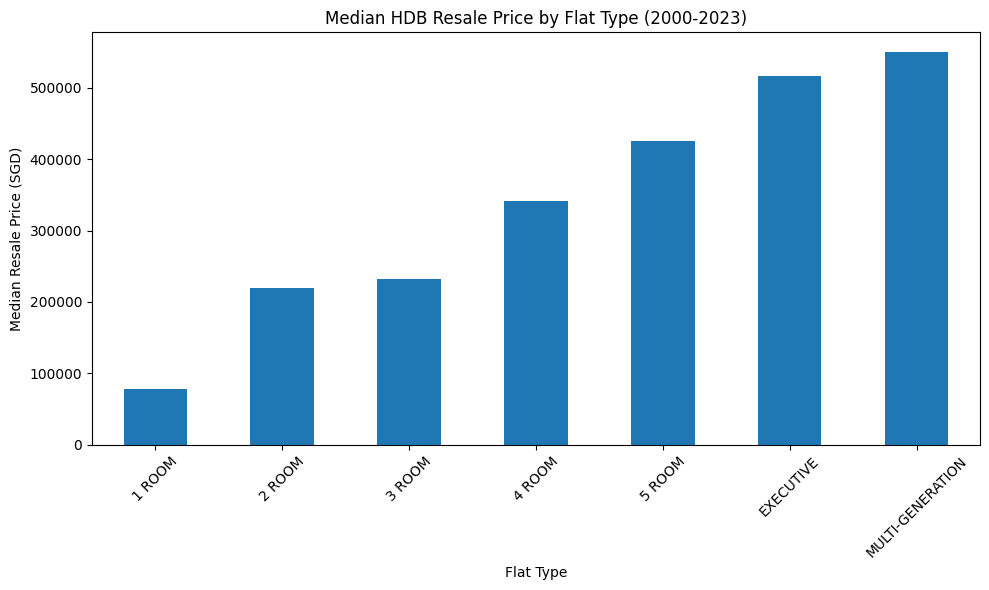

In [21]:
# Purpose: To compare median HDB resale prices across different flat types.
# Calculate median resale price by flat type
flat_type_prices = df_analysis.groupby('flat_type')['resale_price'].median()

# Sort prices from lowest to highest
flat_type_prices = flat_type_prices.sort_values()

# Display results
print("Median Resale Price by Flat Type:")
print(flat_type_prices)

# Create bar chart
plt.figure(figsize=(10, 6))
flat_type_prices.plot(kind='bar')

# Add title and labels
plt.title('Median HDB Resale Price by Flat Type (2000-2023)')
plt.xlabel('Flat Type')
plt.ylabel('Median Resale Price (SGD)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Result: Multi-generation flats had the highest median resale price
# at $550,000, while 1-room flats had the lowest at $78,000.

Median Resale Price by Flat Type in 2023:
flat_type
1 ROOM              241500.0
2 ROOM              320000.0
3 ROOM              390000.0
4 ROOM              550000.0
5 ROOM              650000.0
EXECUTIVE           815000.0
MULTI-GENERATION    975000.0
Name: resale_price, dtype: float64


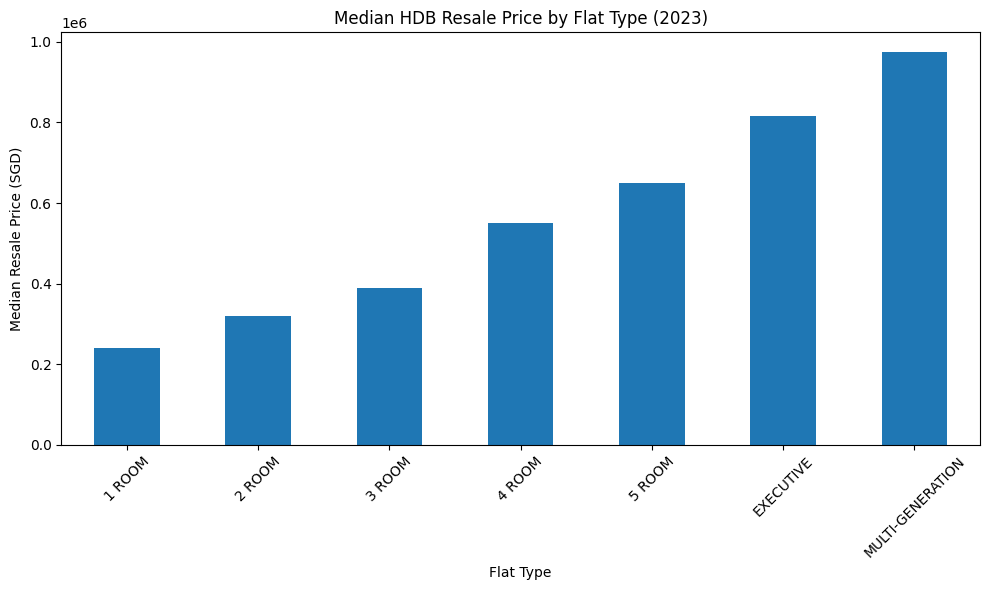

In [25]:
# Purpose: To compare median resale prices by flat type in 2023.
# Calculate median resale prices by flat type
flat_prices_2023 = df_2023.groupby('flat_type')['resale_price'].median()

# Sort from lowest to highest
flat_prices_2023 = flat_prices_2023.sort_values()

# Display results
print("Median Resale Price by Flat Type in 2023:")
print(flat_prices_2023)

# Create bar chart
plt.figure(figsize=(10, 6))
flat_prices_2023.plot(kind='bar')

# Add chart title and labels
plt.title('Median HDB Resale Price by Flat Type (2023)')
plt.xlabel('Flat Type')
plt.ylabel('Median Resale Price (SGD)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Result: Multi-generation flats had the highest median resale price
# at $975,000, while 1-room flats had the lowest at $241,500 in 2023.

Median Price per sqm by Flat Type in 2023:
flat_type
5 ROOM              5472.701754
EXECUTIVE           5602.739726
3 ROOM              5684.931507
4 ROOM              5806.451613
MULTI-GENERATION    5880.503145
2 ROOM              7021.276596
1 ROOM              7790.322581
Name: price_per_sqm, dtype: float64


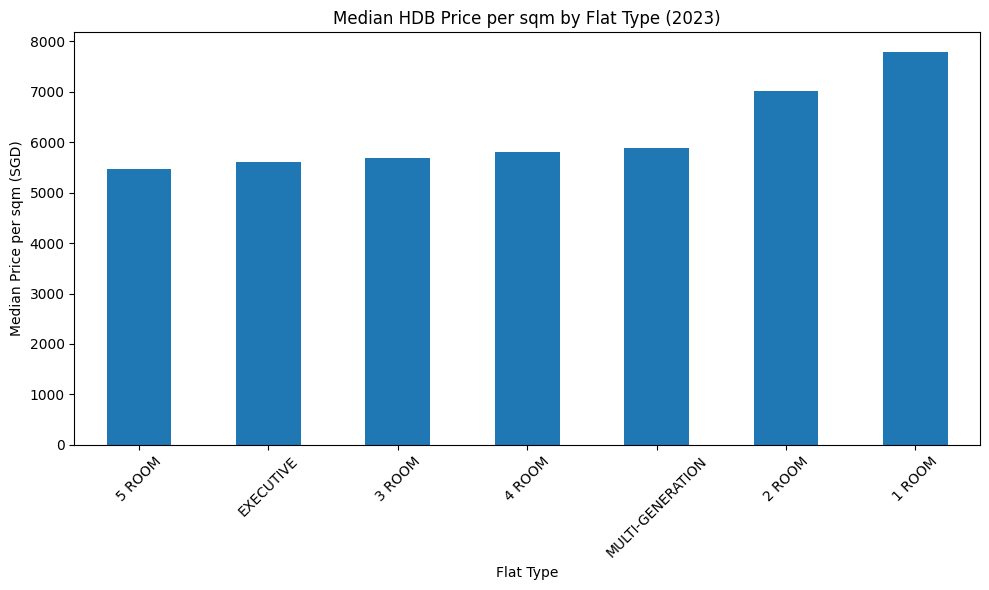

In [29]:
# Purpose: To compare the median price per sqm across HDB flat types in 2023.
# Calculate median price per sqm by flat type
flat_psm_2023 = df_2023.groupby('flat_type')['price_per_sqm'].median()

# Sort from lowest to highest
flat_psm_2023 = flat_psm_2023.sort_values()

# Display results
print("Median Price per sqm by Flat Type in 2023:")
print(flat_psm_2023)

# Create bar chart
plt.figure(figsize=(10, 6))
flat_psm_2023.plot(kind='bar')

# Add chart title and labels
plt.title('Median HDB Price per sqm by Flat Type (2023)')
plt.xlabel('Flat Type')
plt.ylabel('Median Price per sqm (SGD)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Result: 1-room flats had the highest median price per sqm
# at $7,790.32, while 5-room flats had the lowest at $5,472.70 in 2023.

Median Price per Square Metre by Town in 2023:
town
QUEENSTOWN         8144.963145
BUKIT MERAH        8111.111111
BUKIT TIMAH        7796.137019
CENTRAL AREA       7671.568627
BISHAN             7189.640411
KALLANG/WHAMPOA    6681.318681
MARINE PARADE      6576.830006
PUNGGOL            6451.612903
BUKIT BATOK        6343.283582
CLEMENTI           6073.276596
SERANGOON          6042.811355
TOA PAYOH          5940.298507
SEMBAWANG          5935.483871
SENGKANG           5927.272727
GEYLANG            5843.244990
HOUGANG            5641.791045
TAMPINES           5625.000000
ANG MO KIO         5617.812293
BEDOK              5521.739130
YISHUN             5481.927711
BUKIT PANJANG      5320.977778
PASIR RIS          5281.696350
JURONG EAST        5241.134752
WOODLANDS          5093.457944
JURONG WEST        5074.078139
CHOA CHU KANG      4951.923077
Name: price_per_sqm, dtype: float64


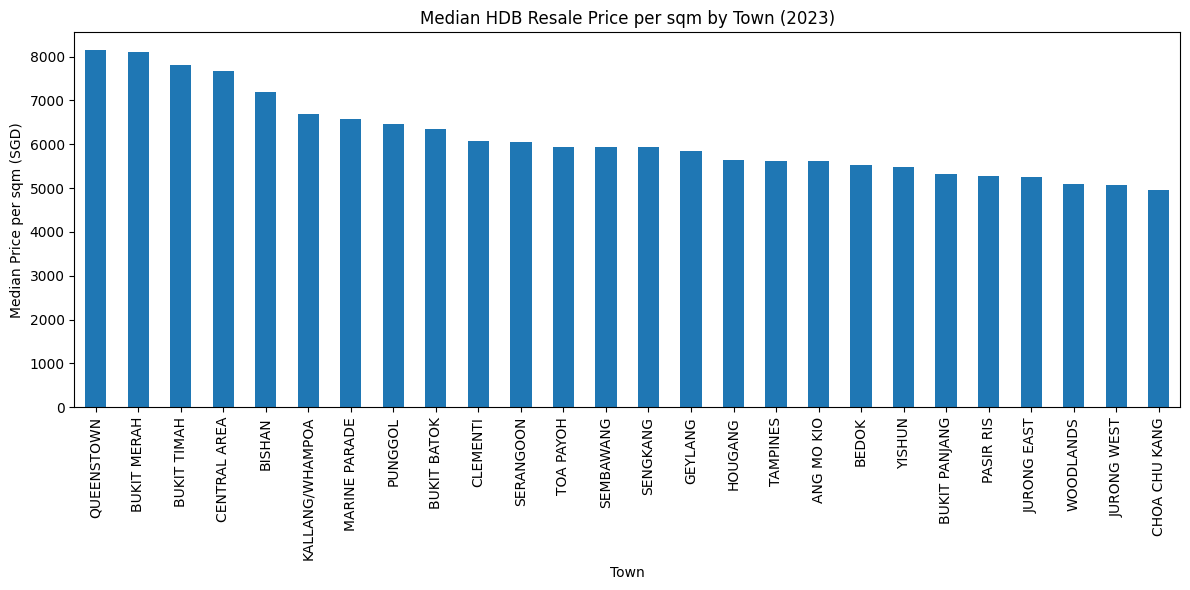

In [24]:
# Purpose: To compare HDB resale prices per square metre across towns in 2023.
# Calculate median price per square metre by town
town_psm_2023 = df_2023.groupby('town')['price_per_sqm'].median()

# Sort prices from highest to lowest
town_psm_2023 = town_psm_2023.sort_values(ascending=False)

# Display results
print("Median Price per Square Metre by Town in 2023:")
print(town_psm_2023)

# Create bar chart
plt.figure(figsize=(12, 6))
town_psm_2023.plot(kind='bar')

# Add title and labels
plt.title('Median HDB Resale Price per sqm by Town (2023)')
plt.xlabel('Town')
plt.ylabel('Median Price per sqm (SGD)')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Result: Queenstown had the highest median price per sqm at $8,144.96,
# while Choa Chu Kang had the lowest at $4,951.92 in 2023.

### Key Finding
HDB resale prices and price per square metre varied across flat types and towns.

In 2023, Queenstown recorded the highest median price per square metre at approximately S$8,145.

This shows that the relative cost of HDB resale flats differs depending on flat type and location.

Price per square metre is used to compare housing costs, but it does not measure affordability based on household income.


## Objective 5: Location-Based Market Performance
To compare HDB resale prices and transaction volumes across different towns in Singapore.


Median Resale Price by Town:
town
PUNGGOL            470000.0
BUKIT TIMAH        455000.0
SENGKANG           433000.0
BISHAN             433000.0
PASIR RIS          405000.0
MARINE PARADE      388000.0
CENTRAL AREA       379000.0
BUKIT MERAH        377000.0
SEMBAWANG          375000.0
TAMPINES           355000.0
CHOA CHU KANG      346000.0
BUKIT PANJANG      340000.0
SERANGOON          340000.0
KALLANG/WHAMPOA    335000.0
HOUGANG            333000.0
QUEENSTOWN         318000.0
JURONG WEST        316000.0
TOA PAYOH          315000.0
WOODLANDS          308000.0
JURONG EAST        308000.0
CLEMENTI           305000.0
BEDOK              300000.0
BUKIT BATOK        295000.0
YISHUN             288000.0
ANG MO KIO         285000.0
GEYLANG            282000.0
Name: resale_price, dtype: float64


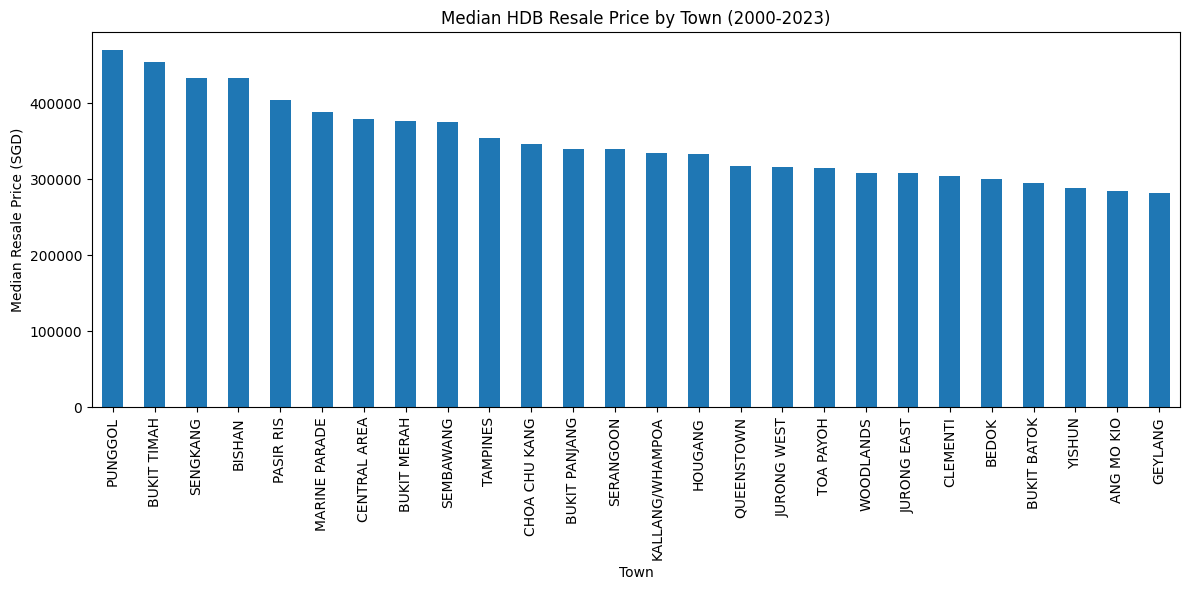

In [22]:
# Purpose: To compare median HDB resale prices across different towns.
# Calculate median resale prices by town
town_prices = df_analysis.groupby('town')['resale_price'].median()

# Sort prices from highest to lowest
town_prices = town_prices.sort_values(ascending=False)

# Display results
print("Median Resale Price by Town:")
print(town_prices)

# Create bar chart
plt.figure(figsize=(12, 6))
town_prices.plot(kind='bar')

# Add chart title and labels
plt.title('Median HDB Resale Price by Town (2000-2023)')
plt.xlabel('Town')
plt.ylabel('Median Resale Price (SGD)')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Result: Punggol had the highest median resale price at $470,000,
# while Geylang had the lowest at $282,000 from 2000 to 2023.

Median Resale Price by Town in 2023:
town
BUKIT TIMAH        825500.0
BISHAN             750000.0
BUKIT MERAH        726500.0
QUEENSTOWN         700000.0
PASIR RIS          635000.0
KALLANG/WHAMPOA    595000.0
PUNGGOL            590000.0
SERANGOON          584000.0
TAMPINES           580000.0
SENGKANG           578444.0
BUKIT BATOK        575000.0
CLEMENTI           550000.0
SEMBAWANG          550000.0
HOUGANG            540000.0
CENTRAL AREA       535000.0
BUKIT PANJANG      530000.0
MARINE PARADE      529444.0
CHOA CHU KANG      528000.0
WOODLANDS          528000.0
JURONG WEST        510000.0
GEYLANG            499000.0
TOA PAYOH          490000.0
YISHUN             480000.0
JURONG EAST        470000.0
BEDOK              465888.0
ANG MO KIO         446944.0
Name: resale_price, dtype: float64


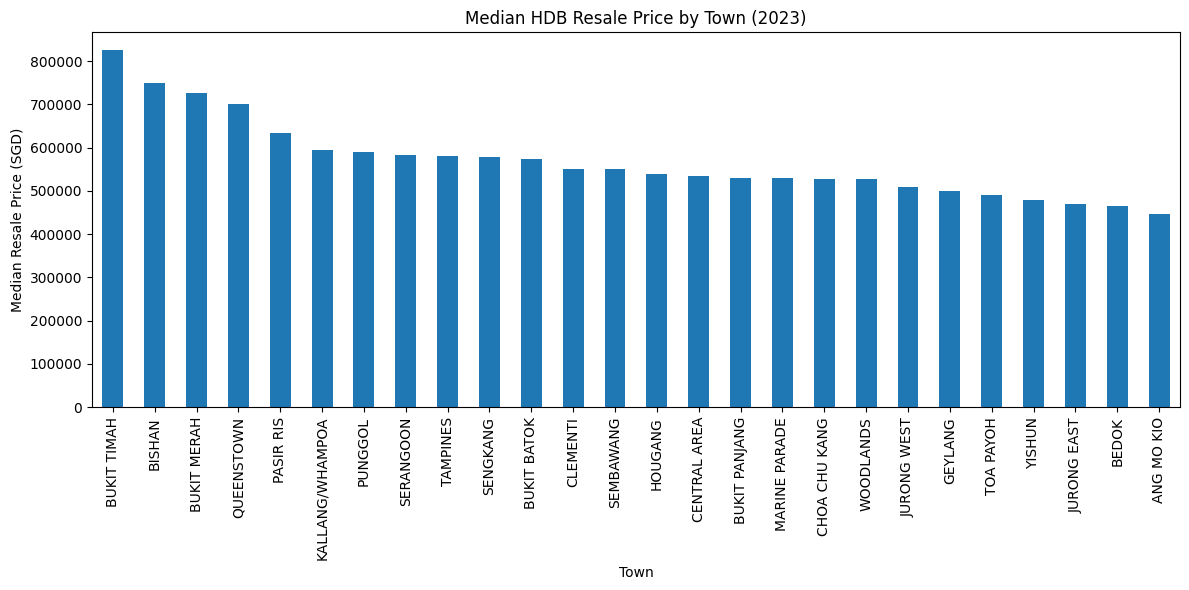

In [23]:
# Purpose: To compare median HDB resale prices across towns in 2023.
# Select transactions from 2023
df_2023 = df_analysis[df_analysis['year'] == 2023]

# Calculate median resale price by town
town_prices_2023 = df_2023.groupby('town')['resale_price'].median()

# Sort prices from highest to lowest
town_prices_2023 = town_prices_2023.sort_values(ascending=False)

# Display results
print("Median Resale Price by Town in 2023:")
print(town_prices_2023)

# Create bar chart
plt.figure(figsize=(12, 6))
town_prices_2023.plot(kind='bar')

# Add chart title and labels
plt.title('Median HDB Resale Price by Town (2023)')
plt.xlabel('Town')
plt.ylabel('Median Resale Price (SGD)')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Result: Bukit Timah had the highest median resale price at $825,500,
# while Ang Mo Kio had the lowest at $446,944 in 2023.

HDB Resale Transactions by Town in 2023:
town
PUNGGOL            2085
WOODLANDS          2058
SENGKANG           1956
YISHUN             1825
TAMPINES           1634
JURONG WEST        1562
HOUGANG            1415
BUKIT BATOK        1410
BEDOK              1311
CHOA CHU KANG      1137
ANG MO KIO         1046
SEMBAWANG          1012
BUKIT MERAH         984
KALLANG/WHAMPOA     783
BUKIT PANJANG       759
TOA PAYOH           721
GEYLANG             636
PASIR RIS           624
QUEENSTOWN          600
CLEMENTI            565
JURONG EAST         468
SERANGOON           420
BISHAN              380
CENTRAL AREA        196
MARINE PARADE       144
BUKIT TIMAH          46
Name: count, dtype: int64


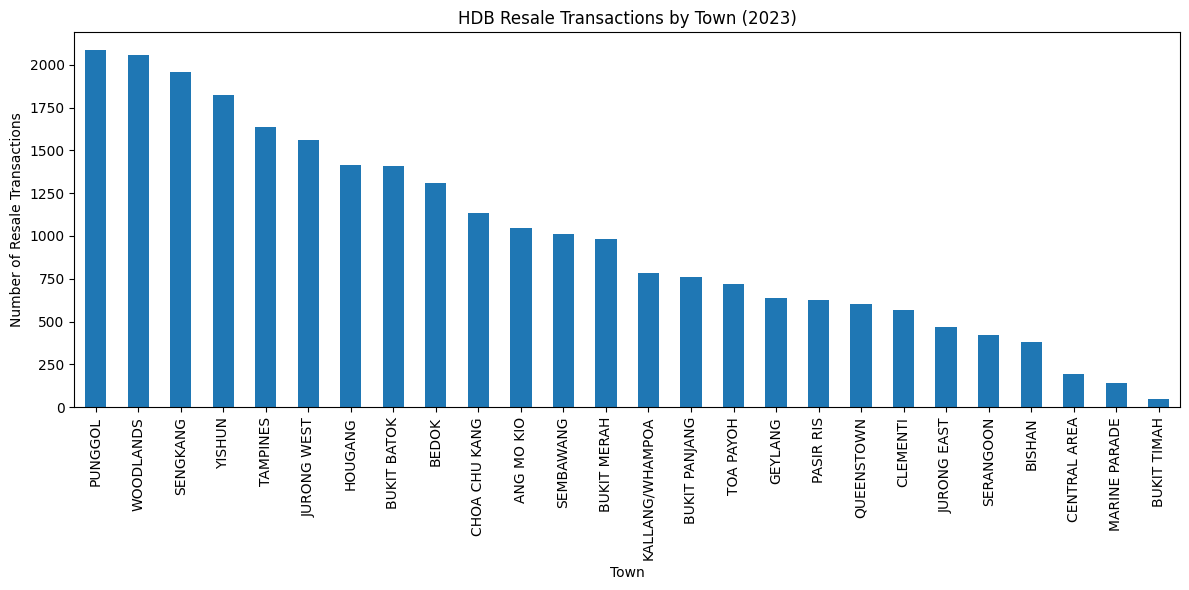

In [35]:
# Purpose: To compare HDB resale transaction volumes across towns in 2023.
# Count transactions by town
town_volume_2023 = df_2023['town'].value_counts()

# Display results
print("HDB Resale Transactions by Town in 2023:")
print(town_volume_2023)

# Create bar chart
plt.figure(figsize=(12, 6))
town_volume_2023.plot(kind='bar')

# Add chart title and labels
plt.title('HDB Resale Transactions by Town (2023)')
plt.xlabel('Town')
plt.ylabel('Number of Resale Transactions')

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Result: Shows differences in resale transaction
# volumes across HDB towns in 2023.


### Key Finding
HDB resale prices and transaction volumes varied across different towns.

In 2023, Bukit Timah recorded the highest median resale price of S$825,500.

The transaction volume chart also shows differences in resale market activity across towns.


# Predictive Analytics – Simple Linear Regression
A simple Linear Regression model is used to predict HDB resale prices based on floor area using 2023 transaction data.

The dataset is divided into 80% training data and 20% testing data.

The model is evaluated using R² Score and Mean Absolute Error (MAE).


In [30]:
# Purpose: Download the prepared HDB dataset for Power BI.
from google.colab import files

files.download('HDB_Resale_Prepared.csv')

# Result: The prepared CSV is downloaded to your computer.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
# Purpose: Predict HDB resale prices using floor area.
# Result: Shows the model's R² score and average prediction error.

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

# Use 2023 transactions
df_2023 = df_analysis[df_analysis['year'] == 2023]

X = df_2023[['floor_area_sqm']]
y = df_2023['resale_price']

# Split data into training (80%) and testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict resale prices
y_pred = model.predict(X_test)

# Check model performance
print("R² Score:", round(r2_score(y_test, y_pred), 3))
print("MAE (SGD):", round(mean_absolute_error(y_test, y_pred), 2))

R² Score: 0.483
MAE (SGD): 91316.53


### Key Finding
The Linear Regression model achieved an R² score of 0.483 and an MAE of S$91,316.53.

The model explains approximately 48.3% of the variation in resale prices.

This shows that floor area has a relationship with resale price, but floor area alone is not enough to make accurate predictions. Other factors such as location, remaining lease and storey range may also affect resale prices.
